In [28]:
# Import necessary libraries
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
grid_schildersbuurt = gpd.read_file(
    "C:/Floor/Documenten/ENV-year-2/Thesis/Data/Schildersbuurt/master_grid_schildersbuurt.gpkg"
)

grid_zorgvliet = gpd.read_file(
    "C:/Floor/Documenten/ENV-year-2/Thesis/Data/Zorgvliet/master_grid_zorgvliet.gpkg"
)

grid_schildersbuurt = grid_schildersbuurt.to_crs("EPSG:28992")
grid_zorgvliet = grid_zorgvliet.to_crs("EPSG:28992")

In [31]:
def determine_time_of_day(column_name):
    """
    Determine the time of day based on the hour in the given column.
    Returns a new column with the time of day categories.
    """
    # Check if it's an LST column
    if not column_name.startswith("LST_"):
        return None
    
    # Extract the time part after the space (e.g., '03:44')
    time_str = column_name.split(" ")[1]
    hour = int(time_str.split(":")[0])
    
    # Use the 6-hour blocks definition
    if 0 <= hour < 6:
        return "Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"

In [32]:
# Calculate the mean LST for each time of day category
lst_columns_schildersbuurt = [col for col in grid_schildersbuurt.columns if col.startswith("LST_")]
lst_columns_zorgvliet = [col for col in grid_zorgvliet.columns if col.startswith("LST_")]

tod_dict_schildersbuurt = {"Night": [], "Morning": [], "Afternoon": [], "Evening": []}
tod_dict_zorgvliet = {"Night": [], "Morning": [], "Afternoon": [], "Evening": []}

for col in lst_columns_schildersbuurt:
    tod = determine_time_of_day(col)
    if tod:
        tod_dict_schildersbuurt[tod].append(col)
for tod, columns in tod_dict_schildersbuurt.items():
    if columns: 
        grid_schildersbuurt[f"LST_Mean_{tod}"] = grid_schildersbuurt[columns].mean(axis=1)
    else:
        grid_schildersbuurt[f"LST_Mean_{tod}"] = np.nan

for col in lst_columns_zorgvliet:
    tod = determine_time_of_day(col)
    if tod:
        tod_dict_zorgvliet[tod].append(col)
for tod, columns in tod_dict_zorgvliet.items():
    if columns: 
        grid_zorgvliet[f"LST_Mean_{tod}"] = grid_zorgvliet[columns].mean(axis=1)
    else:
        grid_zorgvliet[f"LST_Mean_{tod}"] = np.nan

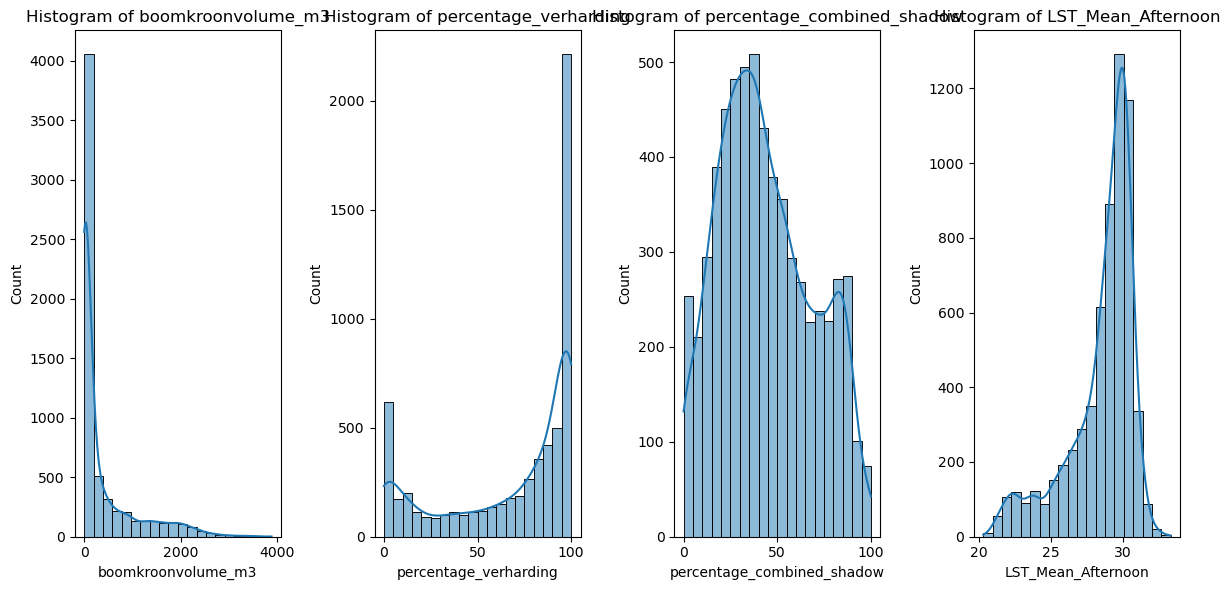

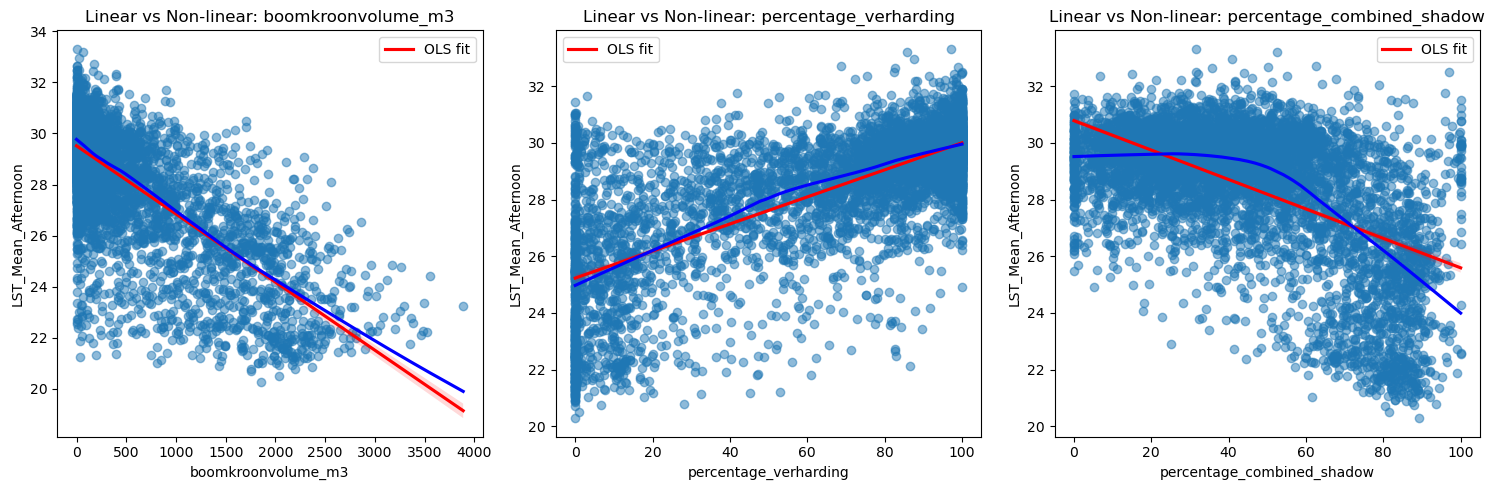

Variance Inflation Factor (VIF) for each feature:
                      feature       VIF
0                       const  1.000000
1          boomkroonvolume_m3  2.547251
2       percentage_verharding  1.842753
3  percentage_combined_shadow  1.753162
/n


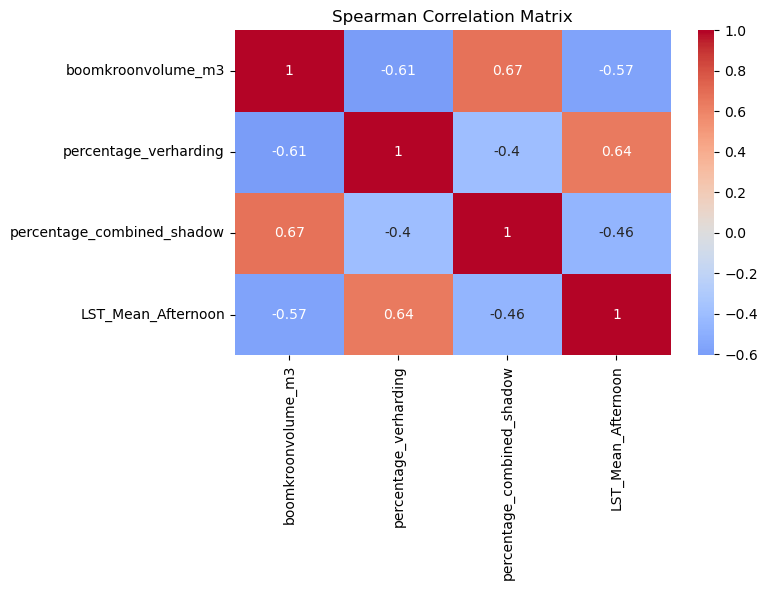

Multiple Linear Regression Model Summary:
                            OLS Regression Results                            
Dep. Variable:     LST_Mean_Afternoon   R-squared:                       0.648
Model:                            OLS   Adj. R-squared:                  0.648
Method:                 Least Squares   F-statistic:                     3823.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:33:18   Log-Likelihood:                -10781.
No. Observations:                6220   AIC:                         2.157e+04
Df Residuals:                    6216   BIC:                         2.160e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------

C:\Users\hoeks\AppData\Local\Temp\ipykernel_29200\3088042094.py:79: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  print(gam.summary())


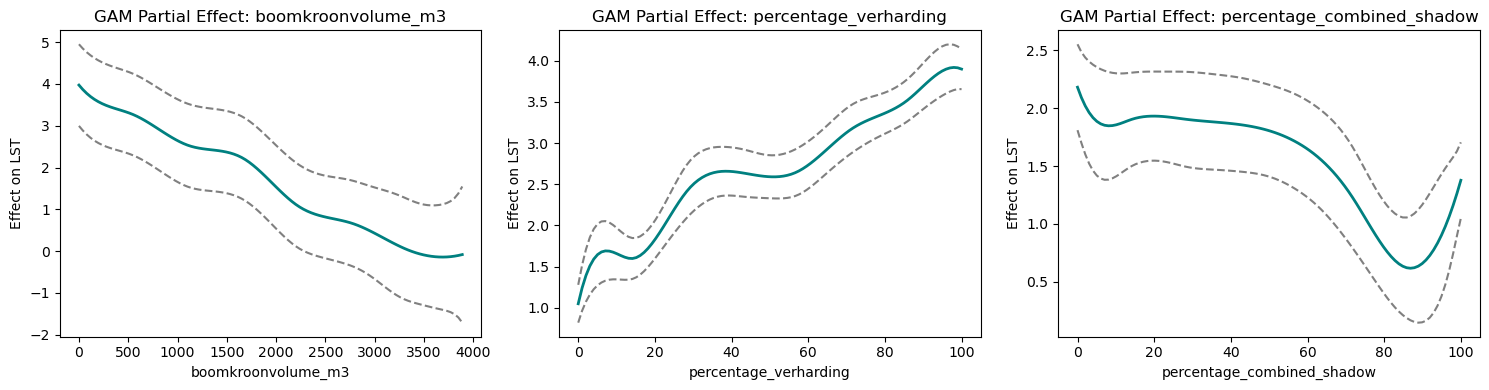

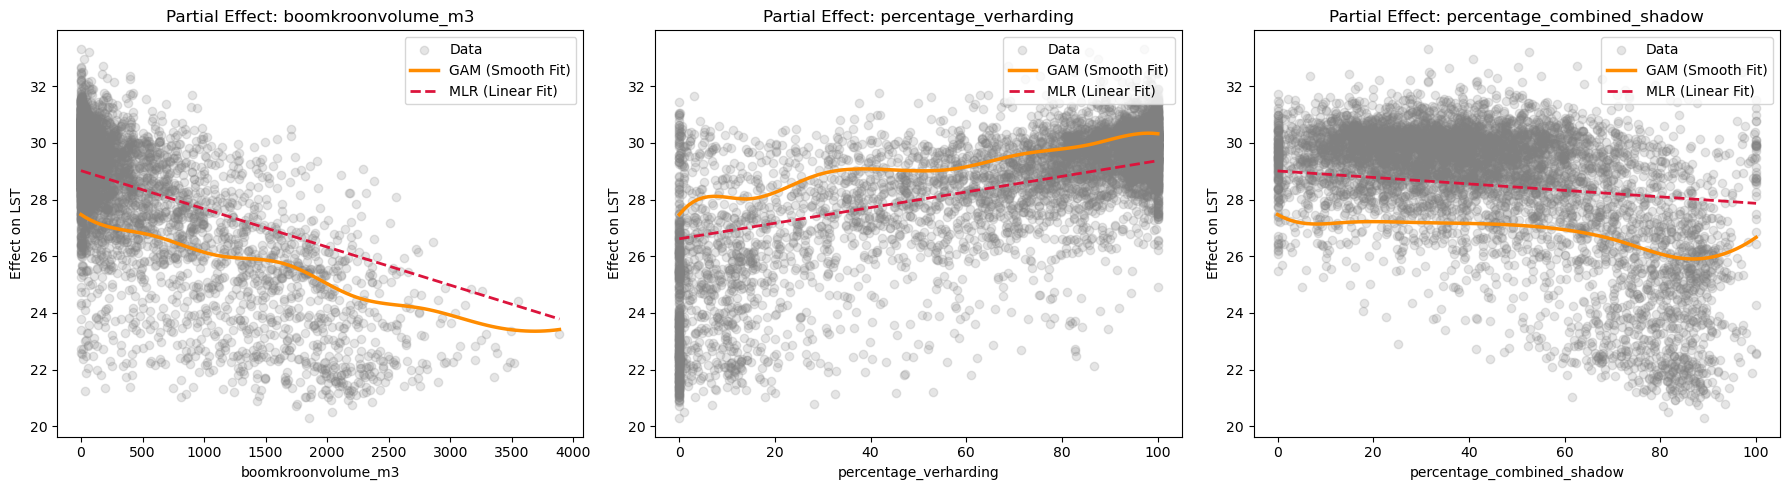

  Model Metric     Value
0   MLR   RMSE  1.369459
1   GAM   RMSE  1.351082
2   MLR     R²  0.648498
3   GAM     R²  0.657869


In [43]:
# Prepare data and define target and prediction columns
target_col = "LST_Mean_Afternoon"
prediction_cols = ["boomkroonvolume_m3", "percentage_verharding", "percentage_combined_shadow"]

grid_whole = pd.concat([grid_schildersbuurt, grid_zorgvliet], ignore_index=True)

df_model = grid_whole.dropna(subset = prediction_cols + [target_col]).copy()

X = df_model[prediction_cols]
y = df_model[target_col]

# check (non)linearity and distributions
## Histograms
plt.figure(figsize=(12, 6))
for i, col in enumerate(prediction_cols + [target_col]):
    plt.subplot(1, len(prediction_cols) + 1, i + 1)
    sns.histplot(df_model[col], kde=True, bins=20)
    plt.title(f"Histogram of {col}")
plt.tight_layout()
plt.show()

## Scatter plots with OLS (linear) and LOWESS (non-linear) fits
fig, axes = plt.subplots(1, len(prediction_cols), figsize=(15, 5))
for i, col in enumerate(prediction_cols):
    sns.regplot(x = df_model[col], y = y, ax = axes[i], scatter_kws = {'alpha':0.5}, line_kws={'color':'red', 'label':'OLS fit'})
    sns.regplot(x = df_model[col], y = y, ax = axes[i], scatter=False, lowess=True, line_kws={'color':'blue', 'label':'LOWESS fit'})
    axes[i].set_title(f"Linear vs Non-linear: {col}")
    axes[i].legend()
plt.tight_layout()
plt.show()

# Check multicollinearity (VIF for MLR)
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X_vif = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print("Variance Inflation Factor (VIF) for each feature:")
print(vif_data)
print("/n")

# Spearman correlation matrix
plt.figure(figsize=(8, 6))
corr_matrix = df_model[prediction_cols + [target_col]].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

# Fit Multiple Linear Regression model (MLR)
X_mlr = sm.add_constant(X)
mlr_model = sm.OLS(y, X_mlr).fit()
mlr_preds = mlr_model.predict(X_mlr)
mlr_residuals = y - mlr_preds

print("Multiple Linear Regression Model Summary:")
print(mlr_model.summary())
print(f"MLR R-squared: {mlr_model.rsquared:.4f}")

#Fit Generalized Additive Model (GAM)
from pygam import LinearGAM, s

gam_formula = s(0, n_splines=10)
for i in range(1, X.shape[1]):
    gam_formula = gam_formula + s(i, n_splines=10)
lambda_grid = np.logspace(-3, 3, 20)
# gam = LinearGAM(gam_formula).gridsearch(X.values, y.values, lam=lambda_grid)
gam = LinearGAM(gam_formula, lam=0.01).fit(X.values, y.values)
print("Optimale lambda's per term:", gam.lam)

gam_preds = gam.predict(X.values)
gam_residuals = y.values - gam_preds
pseudo_r2 = gam.statistics_['pseudo_r2']

print("Generalized Additive Model (GAM) Summary:")
print(f"GAM Explained Deviance: {pseudo_r2['explained_deviance']:.4f}")
print(gam.summary())


# Visualize GAM partial dependence plots
fig, axes = plt.subplots(1, len(prediction_cols), figsize=(15, 4))
for i, col in enumerate(prediction_cols):
    XX = gam.generate_X_grid(term=i)
    pdep, confi = gam.partial_dependence(term=i, X = XX, width=0.95)
    axes[i].plot(XX[:, i], pdep, color='teal', linewidth=2)
    axes[i].plot(XX[:, i], confi[:, 0], color='grey', linestyle='--')
    axes[i].plot(XX[:, i], confi[:, 1], color='grey', linestyle='--')
    axes[i].set_title(f"GAM Partial Effect: {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Effect on LST")
plt.tight_layout()
plt.show()

from sklearn.metrics import mean_squared_error, r2_score

fig, axes = plt.subplots(1, len(prediction_cols), figsize=(18, 5))

for i, col in enumerate(prediction_cols):
    # 1. Scatter of raw data (using partial residual approach or just raw data)
    axes[i].scatter(X[col], y, alpha=0.2, color='gray', label='Data')
    
    # 2. Get smooth partial dependence from the GAM for this specific feature
    # pygam lets you get the smooth function values directly
    XX = gam.generate_X_grid(term=i)
    axes[i].plot(XX[:, i], gam.predict(XX), color='darkorange', label='GAM (Smooth Fit)', linewidth=2.5)
    
    # For MLR linear slope visualization on this single dimension
    # (Showing the marginal linear coefficient slope)
    mlr_slope = mlr_model.params[col]
    mlr_intercept_slice = mlr_model.params['const'] + np.sum([
        mlr_model.params[c] * X[c].mean() for c in prediction_cols if c != col
    ])
    x_sorted = np.sort(X[col])
    mlr_line = mlr_intercept_slice + mlr_slope * x_sorted
    axes[i].plot(x_sorted, mlr_line, color='crimson', label='MLR (Linear Fit)', linewidth=2.0, linestyle='--')

    axes[i].set_title(f"Partial Effect: {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Effect on LST")
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()

# ==========================================
# 2. METRICS COMPARISON BAR CHART
# ==========================================
metrics_data = {
    'Model': ['MLR', 'GAM', 'MLR', 'GAM'],
    'Metric': ['RMSE', 'RMSE', 'R²', 'R²'],
    'Value': [
        np.sqrt(mean_squared_error(y, mlr_preds)),
        np.sqrt(mean_squared_error(y, gam_preds)),
        r2_score(y, mlr_preds),
        r2_score(y, gam_preds)
    ]
}
df_metrics = pd.DataFrame(metrics_data)
print(df_metrics)